# Financial Analysis of Microsoft, Tesla and Apple (2023 to 2025)

**Goal:** Analyse key financial data from 10-K filings to find trends and insights that can support an AI-powered financial chatbot for Global Finance Corp (GFC).

**Data source:** 10-K filings from SEC EDGAR, extracted manually into Excel and saved as CSV. All figures are in millions of US dollars.

In [10]:
from google.colab import files
uploaded = files.upload()

Saving financial_data.csv to financial_data (1).csv


In [11]:
import pandas as pd

df = pd.read_csv('financial_data.csv')
df

,Company,Year,Total Revenue,Net Income,Total Assets,Total Liabilities,Operating Cash Flow,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13
0,Microsoft,2023.0,211915.0,72361.0,411976.0,205753.0,87582.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Microsoft,2024.0,245122.0,88136.0,512163.0,243686.0,118548.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Microsoft,2025.0,281724.0,101832.0,619003.0,275524.0,136162.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Tesla,2023.0,96773.0,14997.0,106618.0,43009.0,13256.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Tesla,2024.0,97690.0,7091.0,122070.0,48390.0,14923.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,Tesla,2025.0,94827.0,3794.0,137806.0,54941.0,14747.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,Apple,2023.0,383285.0,96995.0,352583.0,290437.0,110543.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,Apple,2024.0,391035.0,93736.0,364980.0,308030.0,118254.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,Apple,2025.0,416161.0,112010.0,359241.0,285508.0,111482.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
df = df.dropna(how='all').dropna(axis=1, how='all')

num_cols = ['Total Revenue', 'Net Income', 'Total Assets', 'Total Liabilities', 'Operating Cash Flow']
df[num_cols] = df[num_cols].astype(int)
df['Year'] = df['Year'].astype(int)

df = df.sort_values(['Company', 'Year']).reset_index(drop=True)
df

,Company,Year,Total Revenue,Net Income,Total Assets,Total Liabilities,Operating Cash Flow
0,Apple,2023,383285,96995,352583,290437,110543
1,Apple,2024,391035,93736,364980,308030,118254
2,Apple,2025,416161,112010,359241,285508,111482
3,Microsoft,2023,211915,72361,411976,205753,87582
4,Microsoft,2024,245122,88136,512163,243686,118548
5,Microsoft,2025,281724,101832,619003,275524,136162
6,Tesla,2023,96773,14997,106618,43009,13256
7,Tesla,2024,97690,7091,122070,48390,14923
8,Tesla,2025,94827,3794,137806,54941,14747


## Year-over-year growth
Percentage change in each metric compared with the previous year, calculated separately for each company.

In [13]:
df['Revenue Growth (%)'] = df.groupby(['Company'])['Total Revenue'].pct_change() * 100
df['Net Income Growth (%)'] = df.groupby(['Company'])['Net Income'].pct_change() * 100
df['Assets Growth (%)'] = df.groupby(['Company'])['Total Assets'].pct_change() * 100
df['Liabilities Growth (%)'] = df.groupby(['Company'])['Total Liabilities'].pct_change() * 100
df['Cash Flow Growth (%)'] = df.groupby(['Company'])['Operating Cash Flow'].pct_change() * 100

growth_cols = ['Revenue Growth (%)', 'Net Income Growth (%)', 'Assets Growth (%)',
               'Liabilities Growth (%)', 'Cash Flow Growth (%)']
df[['Company', 'Year'] + growth_cols].round(2)

,Company,Year,Revenue Growth (%),Net Income Growth (%),Assets Growth (%),Liabilities Growth (%),Cash Flow Growth (%)
0,Apple,2023,NaN,NaN,NaN,NaN,NaN
1,Apple,2024,2.02,-3.36,3.52,6.06,6.98
2,Apple,2025,6.43,19.50,-1.57,-7.31,-5.73
3,Microsoft,2023,NaN,NaN,NaN,NaN,NaN
4,Microsoft,2024,15.67,21.80,24.32,18.44,35.36
5,Microsoft,2025,14.93,15.54,20.86,13.07,14.86
6,Tesla,2023,NaN,NaN,NaN,NaN,NaN
7,Tesla,2024,0.95,-52.72,14.49,12.51,12.58
8,Tesla,2025,-2.93,-46.50,12.89,13.54,-1.18


## Financial health ratios
Ratios make companies of different sizes comparable:
- **Net Profit Margin:** how much of each dollar of revenue becomes profit.
- **Debt Ratio:** total liabilities as a share of total assets (higher means more reliance on borrowing).
- **Cash Flow to Net Income:** operating cash compared with reported profit (above 1 means profit is backed by real cash).

In [14]:
df['Net Profit Margin (%)'] = df['Net Income'] / df['Total Revenue'] * 100
df['Debt Ratio (%)'] = df['Total Liabilities'] / df['Total Assets'] * 100
df['Cash Flow to Net Income'] = df['Operating Cash Flow'] / df['Net Income']

ratio_cols = ['Net Profit Margin (%)', 'Debt Ratio (%)', 'Cash Flow to Net Income']
df[['Company', 'Year'] + ratio_cols].round(2)

,Company,Year,Net Profit Margin (%),Debt Ratio (%),Cash Flow to Net Income
0,Apple,2023,25.31,82.37,1.14
1,Apple,2024,23.97,84.40,1.26
2,Apple,2025,26.92,79.48,1.00
3,Microsoft,2023,34.15,49.94,1.21
4,Microsoft,2024,35.96,47.58,1.35
5,Microsoft,2025,36.15,44.51,1.34
6,Tesla,2023,15.50,40.34,0.88
7,Tesla,2024,7.26,39.64,2.10
8,Tesla,2025,4.00,39.87,3.89


## Company comparison (2023 to 2025 averages)

In [15]:
# Average performance per company across the 3 years
summary = df.groupby('Company').agg(
    Avg_Revenue_Growth=('Revenue Growth (%)', 'mean'),
    Avg_Net_Income_Growth=('Net Income Growth (%)', 'mean'),
    Avg_Profit_Margin=('Net Profit Margin (%)', 'mean'),
    Avg_Debt_Ratio=('Debt Ratio (%)', 'mean'),
    Total_Op_Cash_Flow=('Operating Cash Flow', 'sum'),
)
summary.round(2)

,Avg_Revenue_Growth,Avg_Net_Income_Growth,Avg_Profit_Margin,Avg_Debt_Ratio,Total_Op_Cash_Flow
Company,,,,,
Apple,4.22,8.07,25.40,82.08,340279
Microsoft,15.30,18.67,35.42,47.34,342292
Tesla,-0.99,-49.61,8.92,39.95,42926


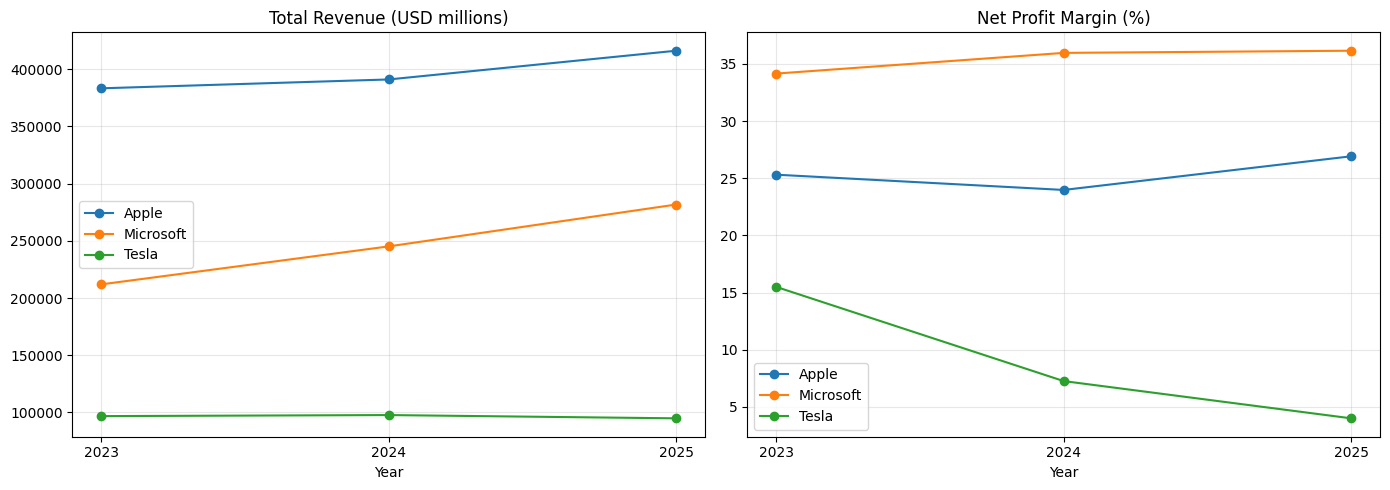

In [16]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for company, data in df.groupby('Company'):
    axes[0].plot(data['Year'], data['Total Revenue'], marker='o', label=company)
    axes[1].plot(data['Year'], data['Net Profit Margin (%)'], marker='o', label=company)

axes[0].set_title('Total Revenue (USD millions)')
axes[1].set_title('Net Profit Margin (%)')
for ax in axes:
    ax.set_xticks([2023, 2024, 2025])
    ax.set_xlabel('Year')
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Findings

**Microsoft: strongest overall performer**
- Revenue grew 15.7% in 2024 and 14.9% in 2025, the fastest of the three.
- Highest net profit margin, rising from 34.2% to 36.2%.
- Total assets grew over 20% a year, partly due to the Activision Blizzard acquisition and data centre investment, while the debt ratio fell from 49.9% to 44.5%.
- Operating cash flow rose 35% in 2024, showing growth is backed by real cash.

**Apple: largest and very stable**
- Highest revenue of the three, reaching \$416.2bn in 2025 with steady growth (2.0% then 6.4%).
- Net income dipped 3.4% in 2024 because of a one-time tax charge of about \$10bn (income tax rose from \$16.7bn to \$29.7bn), then recovered with 19.5% growth in 2025.
- Highest debt ratio (around 80%), mainly because Apple spends heavily on share buybacks rather than due to financial weakness. Operating cash flow of over $110bn a year comfortably covers its obligations.

**Tesla: declining profitability**
- Revenue was flat in 2024 (+0.9%) and fell 2.9% in 2025.
- Net income fell 52.7% in 2024 and 46.5% in 2025 (from \$15.0bn to \$3.8bn), and the profit margin dropped from 15.5% to 4.0%. Part of the 2023 profit came from a one-time tax benefit of about $5bn.
- Positives: the lowest debt ratio (around 40%) and stable operating cash flow of about \$14.7bn, well above net income.
